# 05 — Annotation schema and data quality

## Objective

Inspect the document and question tables, validate their basic schema and relationships, and determine whether the project has verified questions ready for evaluation.

## Concept

An evaluation is only meaningful if question IDs are unique, document references resolve, evidence pages are valid physical page numbers, and only human-verified questions are scored. An empty evaluation set is a valid project state; it must become an explicit readiness result rather than fabricated metrics.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
ANNOTATIONS_DIR = PROJECT_ROOT / "data" / "annotations"

## Execution — load the declared data tables

In [2]:
documents = pd.read_csv(ANNOTATIONS_DIR / "documents.csv")
questions = pd.read_csv(ANNOTATIONS_DIR / "questions.csv")
illustrative_questions = pd.read_csv(
    ANNOTATIONS_DIR / "examples" / "questions_illustrative.csv"
)

print("Documents:", documents.shape)
print("Evaluation questions:", questions.shape)
print("Illustrative rows (never scored):", illustrative_questions.shape)
display(documents[["doc_id", "title", "source_kind", "page_count", "status"]])

Documents: (3, 12)
Evaluation questions: (0, 14)
Illustrative rows (never scored): (5, 14)


,doc_id,title,source_kind,page_count,status
0,D001,"The prior distribution (Bayesian statistics, c...",born_digital,68,candidate
1,D002,EPA sample letter on drinking water (scanned),scanned,3,candidate
2,D003,"Apple Inc. Form 10-K, fiscal year ended 2023-0...",born_digital,74,candidate


## Inspection — corpus composition

This chart describes only the registered documents. It is not an evaluation result.

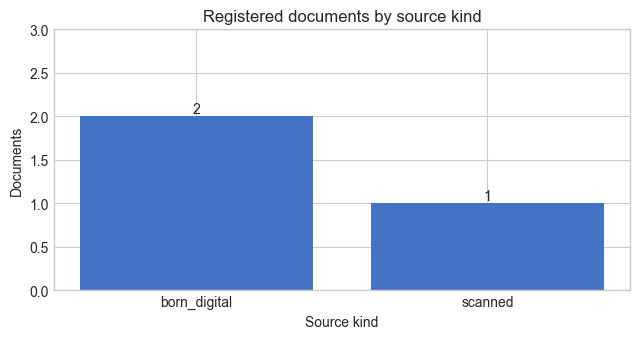

In [3]:
kind_counts = documents["source_kind"].value_counts()
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(kind_counts.index, kind_counts.values, color="#4472C4")
ax.set_title("Registered documents by source kind")
ax.set_xlabel("Source kind")
ax.set_ylabel("Documents")
ax.set_ylim(0, max(kind_counts.values) + 1)
for position, count in enumerate(kind_counts.values):
    ax.text(position, count, str(count), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## Implementation — explicit validation checks

These notebook checks make the assumptions visible. The existing Python tests remain an untouched regression baseline, but the notebook does not import them.

In [4]:
required_document_columns = {
    "doc_id", "file_path", "title", "source_kind", "page_count", "status"
}
required_question_columns = {
    "question_id", "doc_id", "split", "question", "evidence_pages",
    "reference_answer", "status", "verified_by"
}

assert required_document_columns.issubset(documents.columns)
assert required_question_columns.issubset(questions.columns)
assert documents["doc_id"].is_unique
assert questions["question_id"].is_unique
assert set(questions["doc_id"].dropna()).issubset(set(documents["doc_id"]))

verified_questions = questions.loc[questions["status"] == "verified"].copy()
if not verified_questions.empty:
    assert verified_questions["verified_by"].notna().all()
    assert verified_questions["verified_by"].astype(str).str.strip().ne("").all()

print("Basic schema and relationship checks passed.")

Basic schema and relationship checks passed.


## Interpretation — evaluation readiness

In [5]:
readiness = {
    "registered_documents": len(documents),
    "selected_documents": int((documents["status"] == "selected").sum()),
    "evaluation_questions": len(questions),
    "verified_questions": len(verified_questions),
    "ready_for_project_evaluation": bool(len(verified_questions) > 0),
}
readiness

{'registered_documents': 3,
 'selected_documents': 0,
 'evaluation_questions': 0,
 'verified_questions': 0,
 'ready_for_project_evaluation': False}

The current readiness flag is expected to be false: the project deliberately has no verified evaluation questions yet. The illustrative CSV demonstrates formatting only and must never be used as ground truth.

## Validation — empty data is not silently treated as success

In [6]:
if questions.empty:
    assert not readiness["ready_for_project_evaluation"]
    print("Evaluation gate correctly remains closed: questions.csv is empty.")
else:
    print(f"Found {len(verified_questions)} verified questions for later evaluation.")

Evaluation gate correctly remains closed: questions.csv is empty.


## Next step

`06_embedding_and_retrieval.ipynb` introduces vector retrieval with a transparent lexical baseline. It teaches vectorization and cosine similarity before an embedding provider is selected.